In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl 
import re

In [13]:
# wb = openpyxl.load_workbook('C:\\Users\\Grira\\OneDrive - Alstom\\Documents\\ELPI+\\ELPI data\\20250822\\test01.xlsx')
wb = openpyxl.load_workbook('c:\\Users\\Grira\\OneDrive - Alstom\\Documents\\ELPI+\\ELPI data\\20250821\\test03.xlsx')
ws = wb.active
print('Total number of rows: '+str(ws.max_row)+'. And total number of columns: '+str(ws.max_column))

Total number of rows: 3950. And total number of columns: 141


In [14]:
# print('The value in cell A4 is: '+ws['A4'].value)

##### Extraction 15 channels

In [15]:
Di_diameter_15 = [ws.cell(row=13,column=i).value for i in range(2,ws.max_column+1)]
Di_diameter_15_without_none = [v for v in Di_diameter_15 if v is not None]

cell_value = ws['A13'].value
# print(cell_value)
match = re.search(r"=([\d\.]+)", cell_value)

if match:
    valeur_extraite = float(match.group(1))
    Di_diameter_15_without_none.insert(0, valeur_extraite)
    n = len(Di_diameter_15_without_none)
    print('Number of channels:', n)
    print('15 Di diameters (µm):', Di_diameter_15_without_none)

Number of channels: 15
15 Di diameters (µm): [0.006, 0.0136, 0.0193, 0.0341, 0.0509, 0.098, 0.17, 0.316, 0.593, 0.914, 1.64, 2.48, 3.67, 5.39, 9.93]


##### Extraction 500 channels

In [16]:
Di_diameter_500 = [ws.cell(row=36,column=i).value for i in range(2,ws.max_column+1)]
Di_diameter_without_none = [v for v in Di_diameter_500 if v is not None]
n = len(Di_diameter_without_none)
print('Number of channels:',n)
print(n,'Di diameters (µm):', Di_diameter_without_none)

Number of channels: 100
100 Di diameters (µm): [0.006227, 0.006706, 0.007223, 0.007779, 0.008378, 0.009023, 0.009718, 0.010466, 0.011272, 0.01214, 0.013075, 0.014082, 0.015166, 0.016334, 0.017592, 0.018947, 0.020406, 0.021977, 0.02367, 0.025492, 0.027456, 0.02957, 0.031847, 0.034299, 0.036941, 0.039785, 0.042849, 0.046149, 0.049702, 0.05353, 0.057652, 0.062092, 0.066873, 0.072023, 0.077569, 0.083543, 0.089976, 0.096905, 0.104367, 0.112404, 0.12106, 0.130382, 0.140423, 0.151236, 0.162882, 0.175425, 0.188934, 0.203484, 0.219153, 0.23603, 0.254205, 0.273781, 0.294864, 0.317571, 0.342026, 0.368364, 0.396731, 0.427282, 0.460185, 0.495623, 0.533789, 0.574895, 0.619165, 0.666845, 0.718197, 0.773503, 0.833068, 0.89722, 0.966313, 1.040725, 1.120868, 1.207183, 1.300144, 1.400265, 1.508095, 1.624228, 1.749305, 1.884014, 2.029096, 2.18535, 2.353637, 2.534883, 2.730087, 2.940322, 3.166748, 3.410609, 3.673249, 3.956115, 4.260763, 4.588871, 4.942246, 5.322833, 5.732728, 6.174188, 6.649643, 7.161711, 

##### Extraction of Date-time

In [17]:
Date_time=[ws.cell(row=i,column=1).value for i in range(43,ws.max_row+1)]
print(Date_time)

[datetime.datetime(2025, 8, 21, 16, 22, 14), datetime.datetime(2025, 8, 21, 16, 22, 15), datetime.datetime(2025, 8, 21, 16, 22, 16), datetime.datetime(2025, 8, 21, 16, 22, 17), datetime.datetime(2025, 8, 21, 16, 22, 18), datetime.datetime(2025, 8, 21, 16, 22, 19), datetime.datetime(2025, 8, 21, 16, 22, 20), datetime.datetime(2025, 8, 21, 16, 22, 21), datetime.datetime(2025, 8, 21, 16, 22, 22), datetime.datetime(2025, 8, 21, 16, 22, 23), datetime.datetime(2025, 8, 21, 16, 22, 24), datetime.datetime(2025, 8, 21, 16, 22, 25), datetime.datetime(2025, 8, 21, 16, 22, 26), datetime.datetime(2025, 8, 21, 16, 22, 27), datetime.datetime(2025, 8, 21, 16, 22, 28), datetime.datetime(2025, 8, 21, 16, 22, 29), datetime.datetime(2025, 8, 21, 16, 22, 30), datetime.datetime(2025, 8, 21, 16, 22, 31), datetime.datetime(2025, 8, 21, 16, 22, 32), datetime.datetime(2025, 8, 21, 16, 22, 33), datetime.datetime(2025, 8, 21, 16, 22, 34), datetime.datetime(2025, 8, 21, 16, 22, 35), datetime.datetime(2025, 8, 21, 

##### Extraction of 100 channels_dN/dlogDp

In [18]:
# Extraire les données des colonnes 39 à 539 pour les lignes 43 à 2550
Normalized_concentration = [
    [ws.cell(row=i, column=j).value for j in range(39, 139)]
    for i in range(43, ws.max_row+1)
]

# Nettoyer et convertir les données en float si possible
Normalized_concentration_clean = []
for row in Normalized_concentration:
    cleaned_row = []
    for val in row:
        try:
            cleaned_row.append(float(val))
        except (TypeError, ValueError):
            cleaned_row.append(0.0)  # Remplace les valeurs non numériques par 0
    Normalized_concentration_clean.append(cleaned_row)

for row in Normalized_concentration[:3]:  # Affiche les 3 premières lignes
    print(row)

# Afficher la taille de la matrice
print(f"\nNombre total de lignes extraites : {len(Normalized_concentration)}")
print(f"Nombre de colonnes par ligne : {len(Normalized_concentration[0]) if Normalized_concentration else 0}")

[454, 632.1, 868.4, 1178, 1606, 2166, 2875, 3738, 4753, 5904, 7092, 8178, 9046, 9641, 9950, 9925, 9444, 8673, 7781, 6863, 5989, 5201, 4535, 4026, 3645, 3369, 3188, 3090, 3067, 3111, 3217, 3384, 3606, 3856, 4121, 4378, 4603, 4770, 4851, 4823, 4688, 4442, 4101, 3690, 3239, 2782, 2343, 1944, 1594, 1297, 1044, 831.1, 652.8, 504.5, 382.5, 282.5, 201.7, 138.9, 91.78, 57.79, 34.48, 19.43, 10.39, 5.321, 2.645, 1.3, 0.6435, 0.3263, 0.1714, 0.09431, 0.05496, 0.03429, 0.02312, 0.01696, 0.01347, 0.01143, 0.01042, 0.01055, 0.01216, 0.01556, 0.02084, 0.02765, 0.03565, 0.04475, 0.05407, 0.06103, 0.06326, 0.06071, 0.05489, 0.04722, 0.03854, 0.02957, 0.02112, 0.01386, 0.008108, 0.003931, 0.00137, 0.0002718, 2.191e-05, 5.043e-07]
[454, 632.1, 868.4, 1178, 1606, 2166, 2875, 3738, 4753, 5904, 7092, 8178, 9046, 9641, 9950, 9925, 9444, 8673, 7781, 6863, 5989, 5201, 4535, 4026, 3645, 3369, 3188, 3090, 3067, 3111, 3217, 3384, 3606, 3856, 4121, 4378, 4603, 4770, 4851, 4823, 4688, 4442, 4101, 3690, 3239, 2782, 

##### Extraction of 500 channels_dN/dlogDp

In [19]:
# # Extraire les données des colonnes 39 à 539 pour les lignes 43 à 2550
# Normalized_concentration = [
#     [ws.cell(row=i, column=j).value for j in range(39, 539)]
#     for i in range(43, ws.max_row+1)
# ]

# # Nettoyer et convertir les données en float si possible
# Normalized_concentration_clean = []
# for row in Normalized_concentration:
#     cleaned_row = []
#     for val in row:
#         try:
#             cleaned_row.append(float(val))
#         except (TypeError, ValueError):
#             cleaned_row.append(0.0)  # Remplace les valeurs non numériques par 0
#     Normalized_concentration_clean.append(cleaned_row)

# for row in Normalized_concentration[:3]:  # Affiche les 3 premières lignes
#     print(row)

# # Afficher la taille de la matrice
# print(f"\nNombre total de lignes extraites : {len(Normalized_concentration)}")
# print(f"Nombre de colonnes par ligne : {len(Normalized_concentration[0]) if Normalized_concentration else 0}")

##### Plot dN/dlogDp en fct du temps

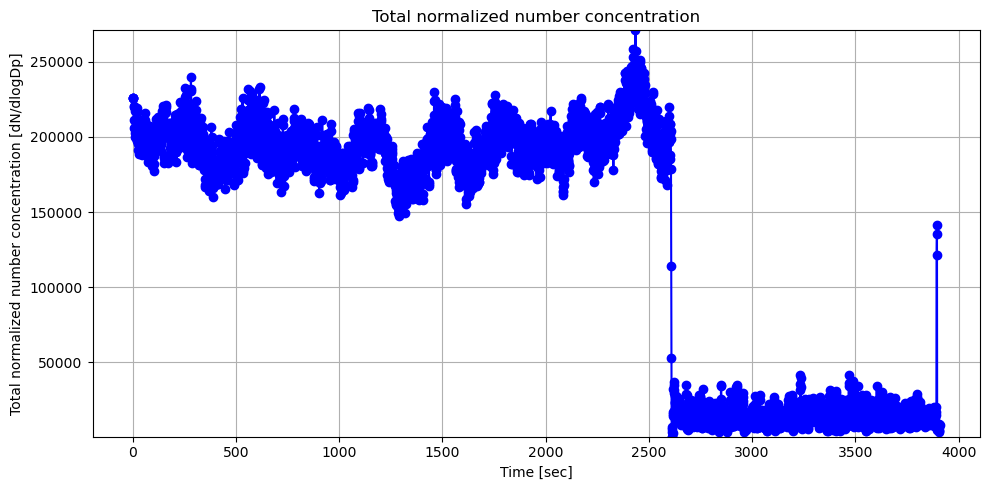

In [20]:
# Calculer la somme de chaque ligne 
Total_Normalized_concentration = [
    sum(float(val) for val in row if isinstance(val, (int, float)))
    for row in Normalized_concentration
]

# Créer les indices correspondants
indices = list(range(1, len(Total_Normalized_concentration) + 1))

# Tracer la courbe
plt.figure(figsize=(10, 5))
plt.plot(indices, Total_Normalized_concentration, marker='o', linestyle='-', color='blue')
plt.title("Total normalized number concentration")
plt.xlabel("Time [sec]")
plt.ylabel("Total normalized number concentration [dN/dlogDp]")
plt.margins(y=0)  
plt.grid(True)
plt.tight_layout()
plt.show()

##### Plot dN/dlogDp en fct du Dp

In [21]:
# Calculer la somme de chaque colonne
somme_colonnes = [sum(col) for col in zip(*Normalized_concentration_clean)]
len(somme_colonnes)

100

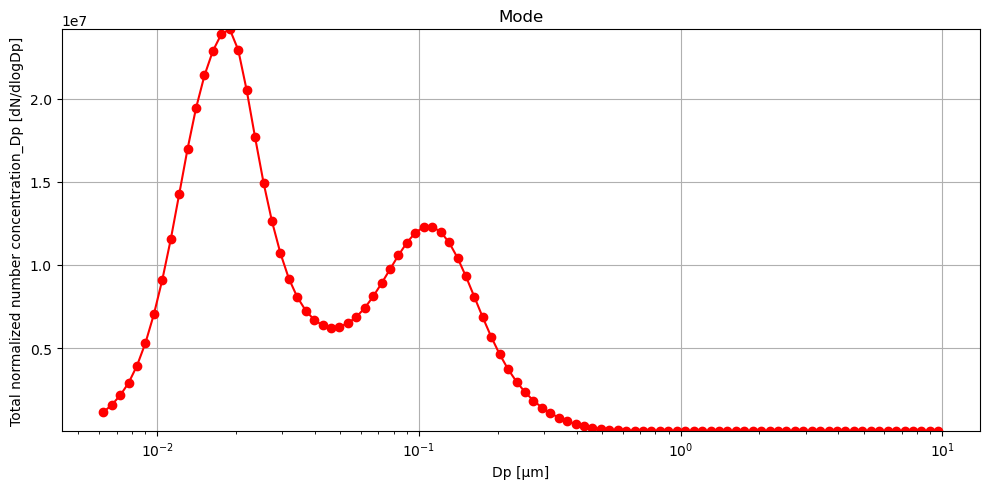

In [22]:
# Calculer la somme de chaque colonne
somme_colonnes = [sum(col) for col in zip(*Normalized_concentration_clean)]

# Tracer la courbe
plt.figure(figsize=(10, 5))
plt.plot(Di_diameter_without_none, somme_colonnes, marker='o', linestyle='-', color='red')
plt.title("Mode")
plt.xscale('log')
plt.xlabel("Dp [µm]")
plt.ylabel("Total normalized number concentration_Dp [dN/dlogDp]")
plt.margins(y=0)  
plt.grid(True)
plt.tight_layout()
plt.show()
